### **PCA — Principal Component Analysis**

**PCA (Principal Component Analysis)** is a dimensionality-reduction technique used to **transform many correlated features into a smaller number of new features called principal components**, while preserving as much of the original variation in the data as possible.

### **Simple idea**

Imagine you have 10 features:

`Feature 1, Feature 2, ..., Feature 10`

Some of them may contain similar information. PCA combines their information into new variables:

`PC1, PC2, PC3, ...`

Usually, you keep only the first few components.

For example:

**10 original features → PCA → 2 principal components**

This makes the dataset easier to visualize and can reduce computational complexity.

### **What are principal components?**

* **PC1** captures the **maximum possible variance** in the data.
* **PC2** captures the next highest variance while being **uncorrelated with PC1**.
* **PC3** captures the next highest variance, and so on.

genui{"learning_viz":{"type_id":"STANDARD_DEVIATION","initial_values":{"sigma":1.5}}}

The key idea is that PCA looks for directions in the data where the observations vary the most.

### **Example**

Suppose you have:

* Height
* Weight
* Waist circumference
* BMI

These variables are likely correlated. PCA might transform them into:

* **PC1:** overall body size
* **PC2:** body-shape differences
* etc.

Instead of using all four original variables, you might retain the first two PCs.

### **Important PCA concepts**

| Concept                      | Meaning                                                |
| ---------------------------- | ------------------------------------------------------ |
| **Principal component**      | A new combination of the original features             |
| **PC1**                      | Direction with the greatest variance                   |
| **PC2**                      | Second greatest variance, orthogonal to PC1            |
| **Explained variance**       | How much information/variation each PC captures        |
| **Loadings**                 | How strongly each original feature contributes to a PC |
| **Dimensionality reduction** | Keeping fewer PCs than original features               |

### **One important rule**

**Standardise your features before PCA** when they are measured on different scales.

For example, if one feature ranges from 0–1 and another from 0–100, the larger-scale feature can dominate PCA unless the data is standardised.

**In one sentence:**

> **PCA reduces the number of features by creating new, uncorrelated components that capture the most important variation in the original data.**


In [1]:
from IPython.display import Image

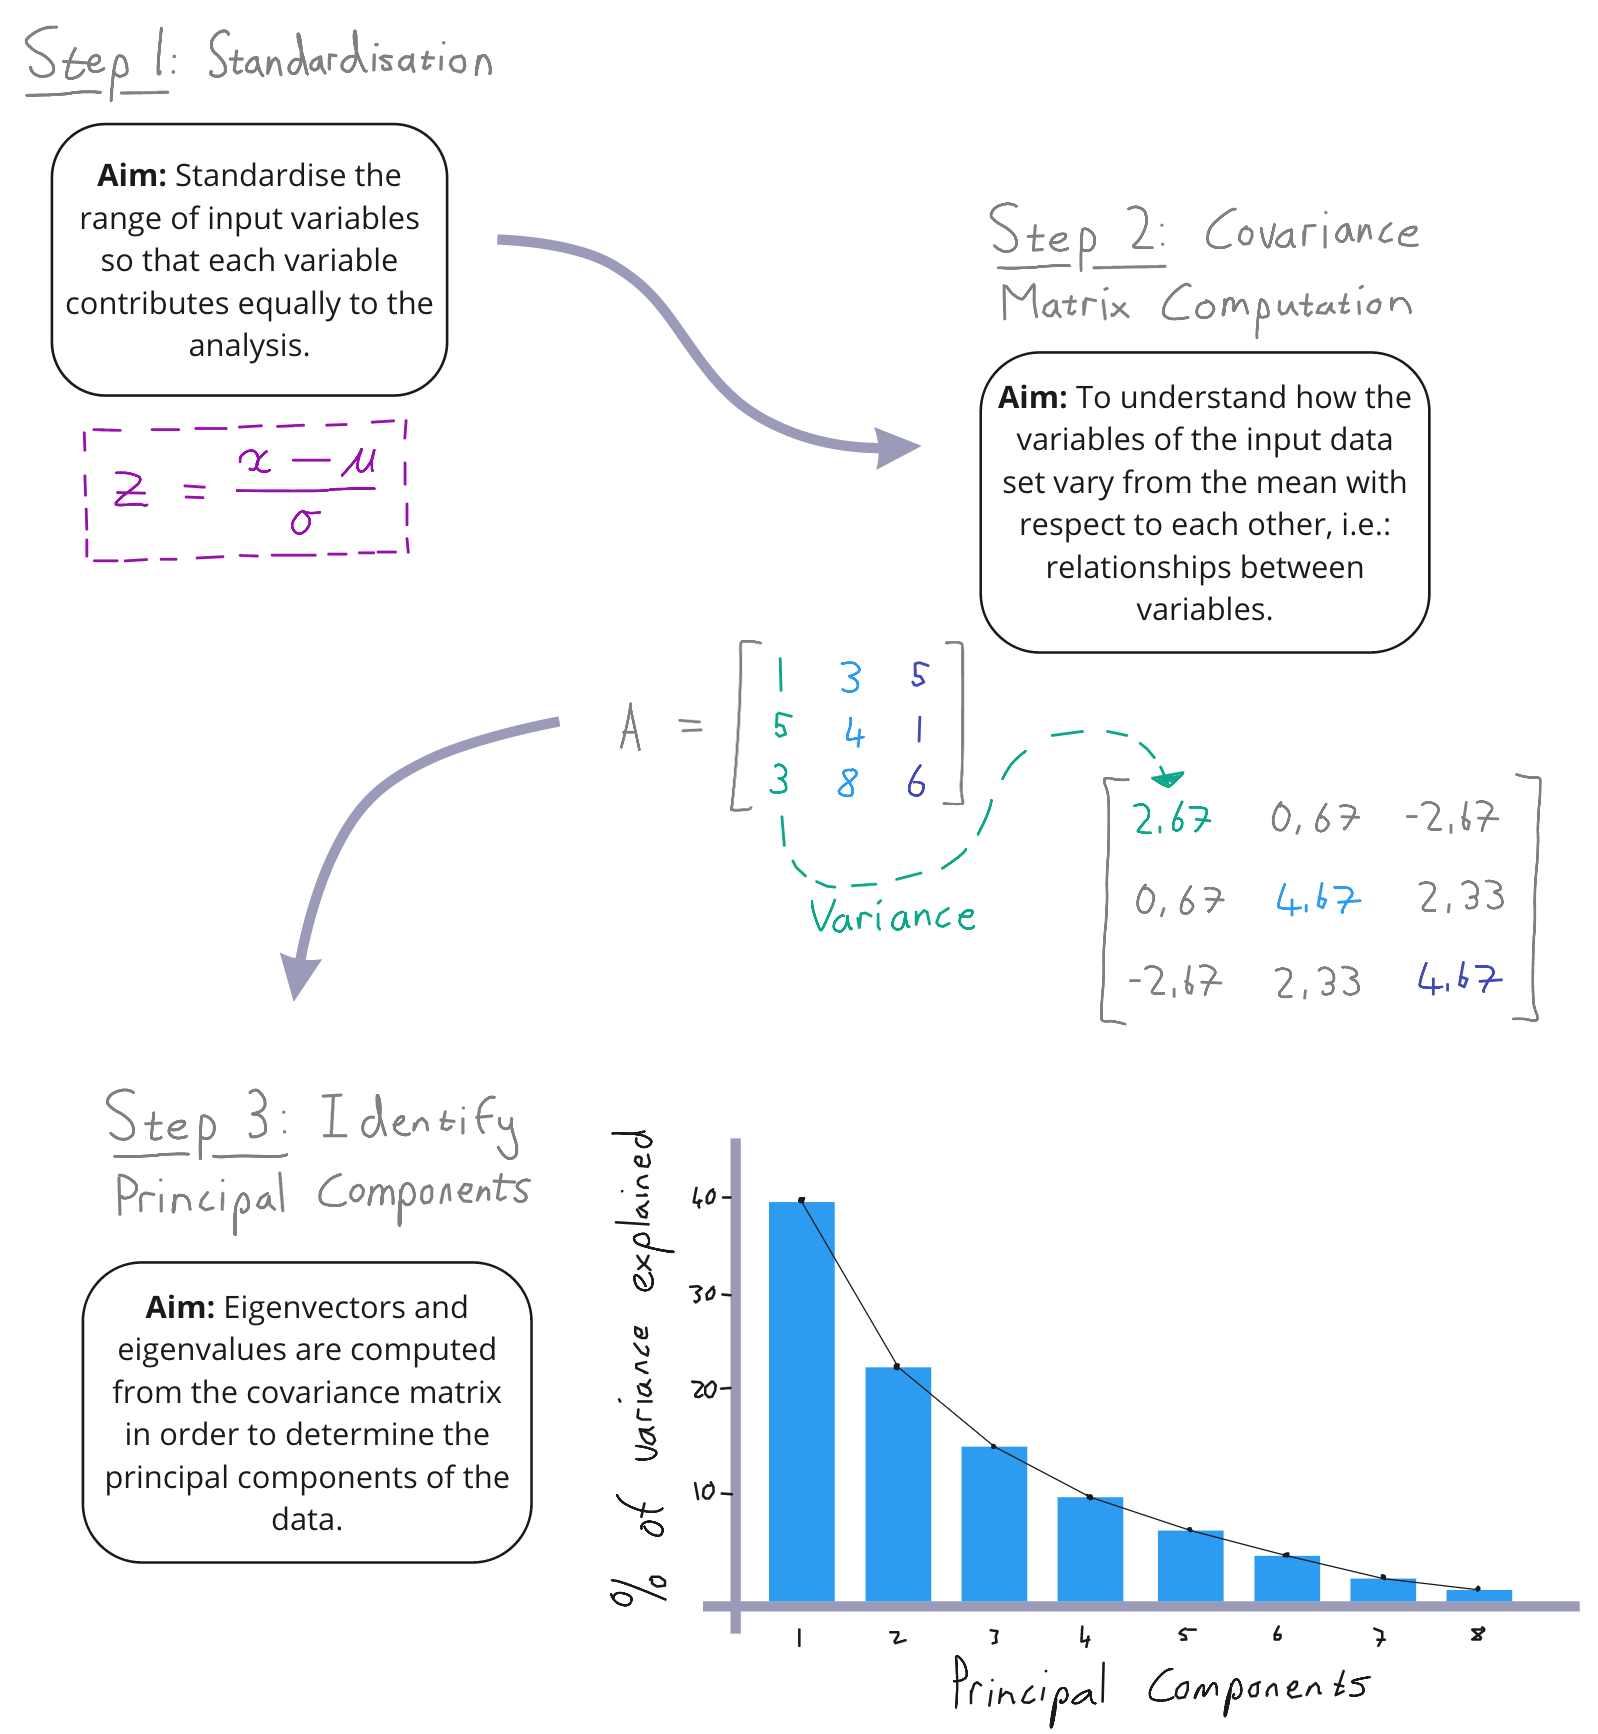

In [2]:
# marimo renders images natively (replaces IPython.display.Image)
Image("https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-pca-diagram.png")

### __Applying PCA to real data__

The dataset we will use is from the US census of 2015. It contains demographic information such as population, proportion of race, gender, income, child poverty, etc, for each county in the US. A county is a geographic area which is larger than a city but smaller than a state. There are over 3000 counties in the dataset, which should provide sufficient information to perform PCA with.

In [6]:
import numpy as np
import pandas as pd
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt
import seaborn as sns

# box plots with plotly.express (marimo renders them natively)
import plotly.express as px

In [10]:
def style_figure(fig, title=None, x_title=None, y_title=None):
    fig.update_layout(
        template="plotly_white",
        paper_bgcolor="white",
        plot_bgcolor="white",
        font=dict(
            family="Arial, sans-serif",
            size=12
        ),
        title=dict(
            text=title,
            font=dict(size=18),
            x=0.5,
            xanchor="center"
        ),
        xaxis=dict(
            title=x_title,
            showgrid=False,
            gridcolor="rgba(0,0,0,0.12)",
            linecolor="rgba(0,0,0,0.5)",
            linewidth=1
        ),
        yaxis=dict(
            title=y_title,
            showgrid=False,
            gridcolor="rgba(0,0,0,0.12)",
            linecolor="rgba(0,0,0,0.5)",
            linewidth=1
        )
    )

    return fig

In [2]:

us_df = pd.read_csv("../data/acs2015_county_data.csv")

In [3]:
us_df.head()

,CensusId,State,County,TotalPop,Men,Women,Hispanic,White,Black,Native,...,Walk,OtherTransp,WorkAtHome,MeanCommute,Employed,PrivateWork,PublicWork,SelfEmployed,FamilyWork,Unemployment
0,1001,Alabama,Autauga,55221,26745,28476,2.6,75.8,18.5,0.4,...,0.5,1.3,1.8,26.5,23986,73.6,20.9,5.5,0.0,7.6
1,1003,Alabama,Baldwin,195121,95314,99807,4.5,83.1,9.5,0.6,...,1.0,1.4,3.9,26.4,85953,81.5,12.3,5.8,0.4,7.5
2,1005,Alabama,Barbour,26932,14497,12435,4.6,46.2,46.7,0.2,...,1.8,1.5,1.6,24.1,8597,71.8,20.8,7.3,0.1,17.6
3,1007,Alabama,Bibb,22604,12073,10531,2.2,74.5,21.4,0.4,...,0.6,1.5,0.7,28.8,8294,76.8,16.1,6.7,0.4,8.3
4,1009,Alabama,Blount,57710,28512,29198,8.6,87.9,1.5,0.3,...,0.9,0.4,2.3,34.9,22189,82.0,13.5,4.2,0.4,7.7


In [4]:
# create short list of unwanted columns
labels = ['CensusId', 'State', 'County']

# declare the features to be all columns, less the unwanted ones from above
features = [col for col in us_df.columns if col not in labels]

### **Scales of measurement**

The most important preprocessing step for our data before any dimensionality reduction may take place is **scaling**.

Scaling data is vitally important because not all variables are measured on the same scales and/or using the same units. For instance, the age variable will have a range of 0 to approximately 95, with a mean somewhere around 40. Income, however, will be measured over a much larger numeric range, well into the thousands or millions, with a very different mean. Let's take a look at box plots of the first few variables to better understand this measurement discrepancy.

In [12]:
fig = px.box(
    us_df[features],
    points=False
)

fig = style_figure(
    fig,
    title="Distribution of Features (Unscaled)",
    x_title="Features",
    y_title="Value"
)

fig.show()

In [13]:
scaled = us_df.copy()
scaled[features] = preprocessing.scale(scaled[features])

In [14]:
# Standardise the selected features
scaled[features] = preprocessing.scale(scaled[features])

# Plot boxplots using scaled data
fig = px.box(
    scaled[features],
    title="Distribution of Features (Scaled)",
    points=False
)

fig = style_figure(
    fig,
    title="Distribution of Features (Scaled)",
    x_title="Features",
    y_title="Standardised Value"
)

fig.show()

In [15]:
# Define PCA object
pca = PCA()

# Fit PCA and transform the scaled data
principal_components = pca.fit_transform(scaled[features])

# Create DataFrame containing the principal components
pca_df = pd.DataFrame(
    principal_components,
    columns=[f"PC{i+1}" for i in range(principal_components.shape[1])]
)

# Add state labels
pca_df["State"] = us_df["State"].values

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

In [16]:
# Create cumulative variance DataFrame
variance_df = pd.DataFrame({
    "Component": range(1, len(cumulative_variance) + 1),
    "Cumulative Variance": cumulative_variance
})

In [ ]:
# Create Plotly line chart
fig = px.line(
    variance_df,
    x="Component",
    y="Cumulative Variance",
    markers=True,
)

# Add 85% reference line
fig.add_hline(
    y=0.85,
    line_dash="dash",
    annotation_text="85% explained variance",
    annotation_position="bottom right"
)

# Apply your Plotly styling
fig = style_figure(
    fig,
    title="Cumulative Explained Variance by Principal Components",
    x_title="Number of Principal Components",
    y_title="Cumulative Explained Variance"
)

fig.show()

As this is a lesson in dimensionality reduction, we'll need to make a compromise: trading variance retained for components kept. Let's set an arbitrary threshold for the desired variance retained of 85% - that is, we want to determine how many principal components will be required to explain 85% of the variance in our dataset. Looking at the graph, it appears roughly 13 components will explain 85% of the data. That is a significant reduction - from 34 features down to 13. Interestingly, it appears that close to 100% of the variance is explained by the first 23 components, itself a significant reduction.

Let's check what the actual number of components would be for 85% variance retention.

In [ ]:
n_components_85 = np.argmax(cumulative_variance >= 0.85) + 1

print(f"Components needed for 85% variance: {n_components_85}")

Components needed for 95% variance: 13


In [22]:
fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="State",
    color_continuous_scale="RdBu"
)

fig = style_figure(
    fig,
    title="PCA: PC1 vs PC2",
    x_title="Principal Component 1",
    y_title="Principal Component 2"
)

fig.show()

### **Putting our dimensionality reduction to use**

We have seen that just 13 components of an original 34 can be used to explain 86.6% of the variance in our dataset. Let us now utilise our reduced dataset, consisting of just 13 components, by using it to build a predictive regressor model.

We will use the feature named `IncomePerCap` as the response variable (the one that we will try to predict). This feature was used in our initial PCA, so we will have to make some changes to the dataset to ensure it is not included this time.

PCA requires features to be scaled, as we mentioned above. But we don't need to scale the response variable which we will use for prediction, as it is not used in PCA. This is good, because leaving the response as it is means any predicted values and associated errors are easier to interpret.

In [26]:
# exclude non-features from data
X = scaled[features]

# set aside response variable (Unscaled!)
y = us_df["IncomePerCap"]

# drop response variable
X = X.drop(['IncomePerCap'], axis=1)

Now, let's split the dataset up into train and test using an arbitrary ratio of 80/20 (train/test, respectively).

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,
    random_state=21
)

In [29]:
# create PCA object with n_components set to 13
pca_reg = PCA(n_components=13)
X_train_1 = pca_reg.fit_transform(X_train)

# fit the PCA model to our data and apply the dimensionality reduction 
# confirm the number of components
pca_reg.n_components_

13

In [30]:
pca_reg.explained_variance_ratio_.sum()

np.float64(0.869422740277808)

In [31]:
X_test_1 = pca_reg.transform(X_test)

In [32]:
# instantiate model with 1000 decision trees
rf = RandomForestRegressor(n_estimators=1000, n_jobs=-1, random_state=101)

# train the model on training data
rf.fit(X_train_1, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",101
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,

In [33]:
y_pred = rf.predict(X_test_1)
errors_reg = abs(y_pred - y_test)
print('Mean Absolute Error:', round(np.mean(errors_reg), 2))

Mean Absolute Error: 1799.64


In [34]:
print(y.agg("median"))

23457.5


In [35]:
print("Predicts IncomePerCap to within", 
    round((round(np.mean(errors_reg), 2)/
    y.agg("median"))*100, 1), 
   "% of its value."
)

Predicts IncomePerCap to within 7.7 % of its value.


The median income value is $23,457, which means our model is able to predict to within ~7% of the actual value on average.

We have managed to make predictions using our reduced dataset, but we have no benchmark metric with which to compare our results. We'll need to train a similar model using our original dataset and check its prediction accuracy.

### **Advantages and disadvantages of PCA**

**Advantages**:
- Effective at finding optimal representation of a dataset with fewer dimensions
- Effective at decreasing redundancy and filtering noise
- Visualisation of datasets with high-dimensionality
- Improves performance of algorithm

**Disadvantages**:
- May result in some loss of information
- Variables may become less interpretable after being transformed